<a href="https://colab.research.google.com/github/Shubhangi5785317/shubhangi-AnalyticsEngineering/blob/main/5_02_practice_weekly_ops.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 5.02 Analytics Engineering: practice test
## Practice: Weekly operations pipeline

## How this practice works

This is a rehearsal for the in-class test. It is **not marked** and nothing is submitted. It works only if you treat it like the real thing: attempt it first, and only then look at the model answer.

This is set to be the same time given in the real test; the same style of notebook and problem; and as close to the real thing as possible. However, of course, the problem is different; the data is different; and you will do it asychronously (which is also different).

- Set a timer for **55 minutes** and work alone. Stop when it rings, then spend **5 minutes** exporting your notebook (see below). Write your start and stop times in the cell under the timing table.
- Work in **Google Colab** and save the notebook as `.ipynb`.
- You may use *any materials, the module GitHub code and any generative AI tool*.
- There is no end-point as such. The task is longer than 55 minutes, so you are completing part of a larger job. Do as much as you can, and do it properly.
- The code itself is not marked. Marks in the real test go on how the task was executed, the methodology applied, and the interpretation of results. Practise that.
- In text cells or comments, include:
  1. **how the code was generated**: the prompt you sent, or the source you used;
  2. **evidence of checking**: what you compared, counted or inspected, and what it showed;
  3. **your interpretation in your own words**.

**Tips**

- Run small pieces and know what output you expect before you run them.
- Put enough text next to the code that someone else can follow your reasoning.
- Follow sound analytics engineering method: understand the grain/rows that you are building around, clean in stages, check before you move on.
- Quality over quantity. A smaller pipeline that you have checked beats a larger one you have not.
- Stay calm. Not finishing is expected.

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Explore and profile the tables |
| 10 to 20 | Plan: grain, joins, cleaning decisions |
| 20 to 45 | Build as far as you can |
| 45 to 55 | Check, reconcile and write up |
| 55 to 60 | Export: **Runtime, then Restart session and run all**; File, Download, .ipynb; put the file in a zip |

In the real test you upload the zip to the Class Test area on my.wbs. Here, keep it so you can compare your work with the model answer afterwards.

**Started at:** 11:00  **Stopped at:** 11:57 **Furthest step I reached (see the brief):** ____

## The data

You have six tables from a fictional food-delivery marketplace, Plateful, which works with restaurants in five UK cities. They cover orders placed from 1 March to 30 June 2026.

| Name in this notebook | What it holds |
| --- | --- |
| `orders` | One record per order: customer, restaurant, when it was placed, delivery fee |
| `order_status_events` | The order's progress through the process, recorded as events |
| `order_lines` | The items inside each order |
| `payments` | Money movements for each order: charges and refunds |
| `restaurants` | Restaurant details: cuisine and city |
| `customers` | Customer details |

All timestamps in all tables are stored in **UTC**.

**How the tables connect**

- `orders` to `order_status_events`, `order_lines` and `payments` on `order_id`
- `orders` to `restaurants` on `restaurant_id`
- `orders` to `customers` on `customer_id`

Check the actual column names in the next cell before you write any joins.

In [3]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/practicesession/plateful-practice.zip"    # link to plateful-practice.zip (the CSV files are inside a folder in the zip)

DATA_DIR = "/content/plateful"

if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/plateful.zip")
    zipfile.ZipFile("/content/plateful.zip").extractall(DATA_DIR)

FILES = {
    "orders": "orders.csv",
    "order_status_events": "order_status_events.csv",
    "order_lines": "order_lines.csv",
    "payments": "payments.csv",
    "restaurants": "restaurants.csv",
    "customers": "customers.csv",
}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}.")

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))

orders: 14,494 rows, 5 columns
    ['order_id', 'customer_id', 'restaurant_id', 'order_ts', 'delivery_fee']
order_status_events: 56,812 rows, 4 columns
    ['event_id', 'order_id', 'status', 'event_ts']
order_lines: 36,120 rows, 5 columns
    ['order_id', 'line_no', 'item_name', 'quantity', 'unit_price']
payments: 16,423 rows, 5 columns
    ['payment_id', 'order_id', 'payment_type', 'amount', 'paid_at']
restaurants: 67 rows, 5 columns
    ['restaurant_id', 'restaurant_name', 'cuisine', 'city', 'effective_from']
customers: 4,200 rows, 3 columns
    ['customer_id', 'signup_date', 'home_city']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each, using only the tables and keys described above. Run them and change them to see what they do. You do not have to use them in your answer.

In [4]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

# Look at the first few rows of a table
display(q("SELECT * FROM orders LIMIT 5"))

# How many rows are there, and how many different order_id values?
display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT order_id) AS n_distinct_orders FROM orders"))

# Join two tables on a key
display(q("""
    SELECT o.order_id, r.restaurant_id
    FROM orders AS o
    JOIN restaurants AS r ON o.restaurant_id = r.restaurant_id
    LIMIT 5
"""))

,order_id,customer_id,restaurant_id,order_ts,delivery_fee
0,O000001,C01161,R052,2026-03-01T09:13:23Z,1.49
1,O000002,C00723,R027,2026-03-01T09:15:33Z,2.49
2,O000003,C00781,R044,2026-03-01T09:23:42Z,0.00
3,O000004,C01430,R049,2026-03-01T09:28:14Z,1.49
4,O000005,C00039,R009,2026-03-01T11:32:35Z,0.00


,n_rows,n_distinct_orders
0,14494,14494


,order_id,restaurant_id
0,O000001,R052
1,O000002,R027
2,O000003,R044
3,O000004,R049
4,O000005,R009


In [5]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

orders = tables["orders"]
display(orders.head())        # first few rows
print(orders.shape)           # (number of rows, number of columns)
print(orders.dtypes)          # data type of each column

# The same join as in Example 1, using pandas
joined = tables["orders"].merge(tables["restaurants"], on="restaurant_id", how="inner")
display(joined[["order_id", "restaurant_id"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT customer_id FROM orders")
print(result["customer_id"].nunique(), "different customer_id values in orders")

,order_id,customer_id,restaurant_id,order_ts,delivery_fee
0,O000001,C01161,R052,2026-03-01T09:13:23Z,1.49
1,O000002,C00723,R027,2026-03-01T09:15:33Z,2.49
2,O000003,C00781,R044,2026-03-01T09:23:42Z,0.00
3,O000004,C01430,R049,2026-03-01T09:28:14Z,1.49
4,O000005,C00039,R009,2026-03-01T11:32:35Z,0.00


(14494, 5)
order_id          object
customer_id       object
restaurant_id     object
order_ts          object
delivery_fee     float64
dtype: object


,order_id,restaurant_id
0,O000001,R052
1,O000002,R027
2,O000003,R044
3,O000004,R049
4,O000005,R009


4073 different customer_id values in orders


## Your brief

**From:** Operations

> We run Plateful, a food-delivery marketplace in five UK cities. We are starting a weekly operations report and need the first layers of a data pipeline behind it: clean tables first, then one reporting table. For each week, show orders, net revenue and average delivery time by cuisine and by city. We also need to know how far we can trust the figures.

**What your final table should look like**

One table with columns for week, cuisine, city, number of orders, net revenue and average delivery time in minutes. State clearly what one row of your table represents.

**Decisions you must make and state**

- Which week does an order belong to?
- Which orders count as orders, and which do not?
- What does "net revenue" mean here, and where does it come from?
- What counts as "delivery time", and for which orders can it be measured?

**A suggested route, in order** (you are not expected to finish)

1. Profile the tables: grain, keys, duplicates, odd values.
2. Build clean tables (a silver layer) with one row per order where that is the grain.
3. Build the one reporting table (gold) from them.
4. Show with checks that the gold table agrees with the source data.
5. If you have time: add cancelled orders and a refund rate to the table, and write automated checks for your clean tables.

## 1. Understand the data

*Look before you build. Write down what you find: what one row of each table represents, how the tables connect, and anything that looks odd or missing.*

Inorder to understand the data first I ran a code to understand what each row of the table looks like so that i can write my interpretations.

what one row of table represents:
order table: One order placed by a customer at a restaurant, including the order time and delivery fee.
order_status_events:	One status event for an order, recording its status and the time that event occurred.
order_lines:	One item line within an order, including the item, quantity and unit price.
payments:	One payment movement associated with an order, such as a charge or refund, including its amount and timestamp.
restaurants	:One restaurant record, including its name, cuisine, city and the date from which that record is effective.
customers:	One customer record, including their signup date and home city.ique customer id, the date that they signed up and their home city

how tables connect:
order table: order id is the primary key but is used as a foreign key in table order lines, payments.

entities:
customer 1 customer can have many orders from many restaurants can make many payments which leads to many events
order 1 order can have 1 customer,restaurant, event and payment
restaurant 1 restaurant can have many customers, orders, events and payments
event 1 event can have 1 customer,order,restauarnt,payment
payment 1 payment can have 1 1 customer,order,restauarnt,event


Things that look odd:
1. restaurant: city names are inconsistnet, cuisine is also inconsistent some are starting with cap some are not, name of restauarnt has diff values to it even though it's the same restauant


In [6]:
#
for table_name, df in tables.items():
    print(f"\nTable: {table_name}")
    display(df.head(20))


Table: orders


,order_id,customer_id,restaurant_id,order_ts,delivery_fee
0,O000001,C01161,R052,2026-03-01T09:13:23Z,1.49
1,O000002,C00723,R027,2026-03-01T09:15:33Z,2.49
2,O000003,C00781,R044,2026-03-01T09:23:42Z,0.00
3,O000004,C01430,R049,2026-03-01T09:28:14Z,1.49
4,O000005,C00039,R009,2026-03-01T11:32:35Z,0.00
5,O000006,C00597,R062,2026-03-01T11:38:04Z,3.49
6,O000007,C02534,R014,2026-03-01T11:46:50Z,0.00
7,O000008,C00839,R043,2026-03-01T11:48:55Z,1.49
8,O000009,C02423,R046,2026-03-01T11:52:27Z,1.49
9,O000010,C03450,R049,2026-03-01T12:09:50Z,3.49



Table: order_status_events


,event_id,order_id,status,event_ts
0,E027809,O007104,accepted,2026-04-29T13:28:57Z
1,E018209,O004658,placed,2026-04-08T19:11:30Z
2,E043792,O011178,accepted,2026-06-02T17:07:47Z
3,E021428,O005468,delivered,2026-04-15T13:43:36Z
4,E037134,O009483,picked_up,2026-05-19T12:18:18Z
5,E051502,O013140,accepted,2026-06-19T20:55:53Z
6,E018523,O004726,delivered,2026-04-09T17:05:15Z
7,E019849,O005067,picked_up,2026-04-11T23:27:01Z
8,E042646,O010888,picked_up,2026-05-31T08:43:00Z
9,E009872,O002516,delivered,2026-03-22T13:34:21Z



Table: order_lines


,order_id,line_no,item_name,quantity,unit_price
0,O000001,1,Ramen,3,12.0
1,O000002,1,Soft drink,1,2.0
2,O000002,2,Side salad,1,3.5
3,O000002,3,Burrito,3,8.0
4,O000003,1,Fries,1,3.0
5,O000003,2,Soft drink,1,2.0
6,O000003,3,Fried rice,1,7.5
7,O000004,1,Burrito,3,8.0
8,O000004,2,Chicken tikka,1,11.0
9,O000004,3,Pad thai,1,10.5


... (2 outputs left out)


Table: restaurants


,restaurant_id,restaurant_name,cuisine,city,effective_from
0,R064,Fresh Vegan 64,Vegan,London,2025-01-01
1,R012,Royal Burgers 12,Burgers,Bristol,2025-01-01
2,R028,Grand Burgers 28,Burgers,Birmingham,2025-01-01
3,R007,Royal Japanese 7,Japanese,Bristol,2025-01-01
4,R026,Corner Indian 26,Indian,London,2025-01-01
5,R005,Urban Thai 5,Thai,London,2025-01-01
6,R021,Grand Thai 21,Thai,LEEDS,2026-05-06
7,R007,Royal Japanese 7,Japanese,London,2026-04-14
8,R029,Royal Thai 29,Thai,Manchester,2025-01-01
9,R056,Little Vegan 56,Vegan,Birmingham,2025-01-01



Table: customers


,customer_id,signup_date,home_city
0,C00001,2024-10-15,London
1,C00002,2025-05-17,Leeds
2,C00003,2026-01-25,Leeds
3,C00004,2024-09-14,London
4,C00005,2024-01-25,Manchester
5,C00006,2025-06-08,London
6,C00007,2025-04-25,London
7,C00008,2024-09-27,London
8,C00009,2025-03-26,Leeds
9,C00010,2025-06-18,Leeds


## 2. Plan

*Before you write the main code, write your plan in your own words: what one row of your final table is, which tables you will join and in what order, how many rows you expect at each step, and how you will handle the problems you found.*

so we need to make a table  where we start week wise, mention in a particular city for a particular cuisine how many orders took place and what was the net revenue and the average delivery time for each order. we get this info from the 1. orders table using the orders id, 2. order status tbale for status because we need to see how many orders actually took place 3. order lines to get quantity 3. using payments table we calculate revenue using each order if and filter it against the payment type
and  to get the delivery time we get using status aswell from order status table, then for cuisine and city we get from thhe restauarnt table.

so i would go with this order:

use orders table for order id, then use status table to get order status and to calculate delivery time. use payments table for calculating net revenue, restaurnts table  for restaurant  id city and cuisine.

to handle the problems i initially saw, i would first for each table check the data once again, check for duplicates and missing values and any other inconsistneces and use code to fix them and later check if i got what i wanted the code to  fix

## 3. Build

*Build as far as you can in the time. Short, re-runnable cells are better than one long cell.*

Add text here as you go along. Show that you are staying in control of the build!

Data exploration:

inorder to understand the data i first wanted to know the descriptive statistics of the all the tables which also provides me with the direction on where i want to start with my cleaning.

In [9]:
for table_name, df in tables.items():
    print(f"\n--- {table_name} ---")
    display(df.describe(include="all"))


--- orders ---


,order_id,customer_id,restaurant_id,order_ts,delivery_fee
count,14494,14494,14494,14494,14494.000000
unique,14494,4073,64,14467,NaN
top,O000001,C01882,R038,2026-04-08T18:30:21Z,NaN
freq,1,13,945,2,NaN
mean,NaN,NaN,NaN,NaN,2.150676
std,NaN,NaN,NaN,NaN,1.104824
min,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,1.490000
50%,NaN,NaN,NaN,NaN,2.490000
75%,NaN,NaN,NaN,NaN,2.990000



--- order_status_events ---


,event_id,order_id,status,event_ts
count,56812,56812,56812,56812
unique,56812,14494,5,56200
top,E027809,O003952,placed,2026-05-17T18:01:06Z
freq,1,6,14494,3



--- order_lines ---


,order_id,line_no,item_name,quantity,unit_price
count,36120,36120.000000,36120,36120.000000,36120.000000
unique,14494,NaN,12,NaN,NaN
top,O014458,NaN,Pad thai,NaN,NaN
freq,4,NaN,3101,NaN,NaN
mean,NaN,1.996152,NaN,1.995903,7.211739
std,NaN,0.998690,NaN,0.813985,3.131357
min,NaN,1.000000,NaN,1.000000,2.000000
25%,NaN,1.000000,NaN,1.000000,5.000000
50%,NaN,2.000000,NaN,2.000000,8.000000
75%,NaN,3.000000,NaN,3.000000,10.500000


... (2 outputs left out)


--- restaurants ---


,restaurant_id,restaurant_name,cuisine,city,effective_from
count,67,67,67,67,67
unique,64,64,15,8,4
top,R007,Royal Japanese 7,Vegan,London,2025-01-01
freq,2,2,9,23,64



--- customers ---


,customer_id,signup_date,home_city
count,4200,4200,4200
unique,4200,794,5
top,C00001,2025-09-13,London
freq,1,11,1541


**Prompt**
"first i want to inspect the data so  give me a code to do the basic descriptive statistics"

in order table:
1. order ts are 14494 but no of them which are unique are 14467 which could indicate duplicate values
In general
1. there's a lot of nan values which could mean missing values but not necessarily

**What these mean**
the order ts  and no of unique are not aligning which could lead to potential data quality issues

**Next steps**
run a code to find out the duplicate values and then investigate further

2. Visualise the data
The next thing i wanted to do was to visualise this data to truly understand any hidden patterns of the data and how the variables look.

**Prompt:**
i now want a code to visualise all these tables, mostly the mean values for numeric ones, I want histograms. i want you to plot this data. i want graphs that  are straightforward, easy to understand. I want to start with the first table only for orders

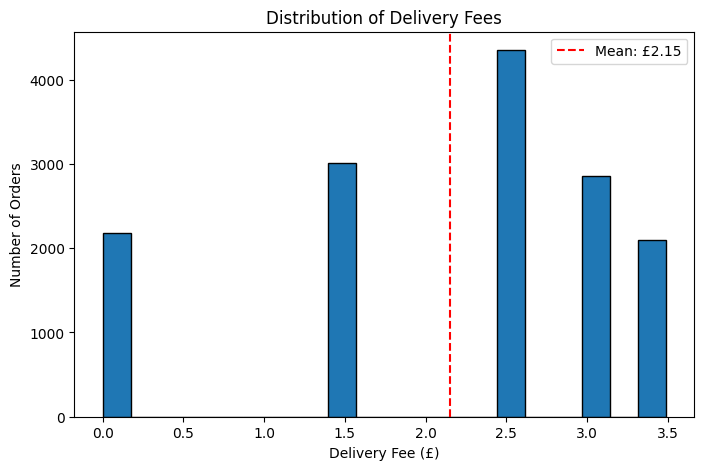

In [11]:
import matplotlib.pyplot as plt

# Select the orders table
df = tables["orders"]

# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(df["delivery_fee"].dropna(), bins=20, edgecolor="black")

# Add a line showing the mean
mean_fee = df["delivery_fee"].mean()
plt.axvline(mean_fee, color="red", linestyle="--",
            label=f"Mean: £{mean_fee:.2f}")

plt.title("Distribution of Delivery Fees")
plt.xlabel("Delivery Fee (£)")
plt.ylabel("Number of Orders")
plt.legend()
plt.show()

Observation: From the graph we can infer that the mean delivery fee in pounds is 2 but 2.5 is the highest

Checking:


Interpretation:

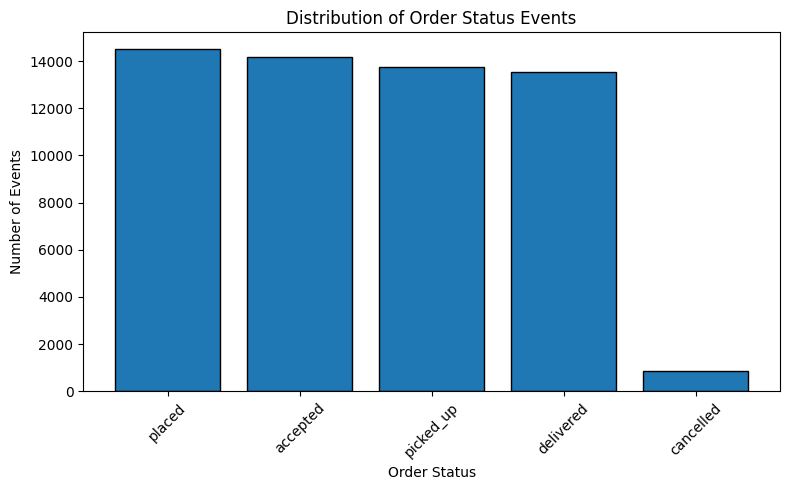

In [12]:
import matplotlib.pyplot as plt

df = tables["order_status_events"]

# Count each order status
status_counts = df["status"].value_counts()

# Plot
plt.figure(figsize=(8, 5))
plt.bar(status_counts.index, status_counts.values, edgecolor="black")

plt.title("Distribution of Order Status Events")
plt.xlabel("Order Status")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In the 2nd table for the status events, the no of events for cancelled seems to be very low, this could indicate having very low  cancellings from customers.

Checking:

Interpretation:


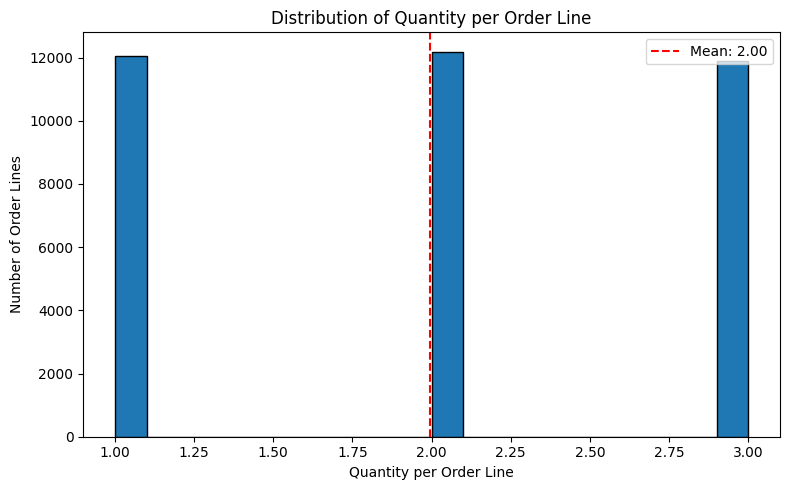

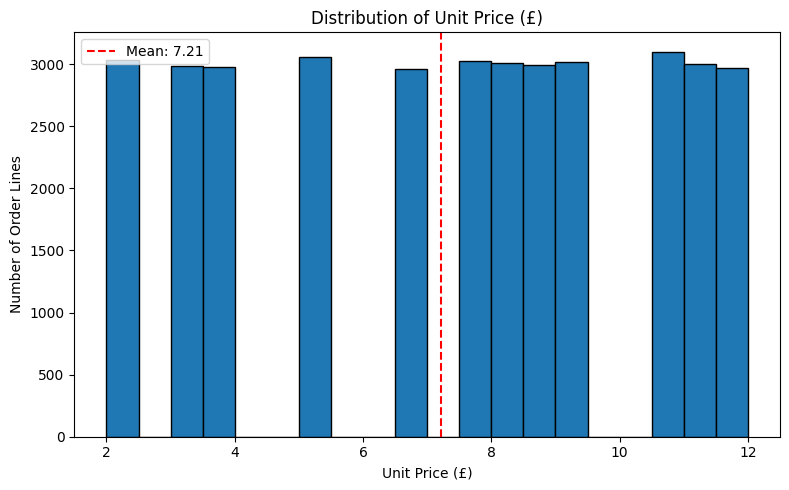

In [13]:
import matplotlib.pyplot as plt

df = tables["order_lines"]

for column, label in [
    ("quantity", "Quantity per Order Line"),
    ("unit_price", "Unit Price (£)")
]:
    mean_value = df[column].mean()

    plt.figure(figsize=(8, 5))
    plt.hist(df[column].dropna(), bins=20, edgecolor="black")

    plt.axvline(
        mean_value,
        color="red",
        linestyle="--",
        label=f"Mean: {mean_value:.2f}"
    )

    plt.title(f"Distribution of {label}")
    plt.xlabel(label)
    plt.ylabel("Number of Order Lines")
    plt.legend()
    plt.tight_layout()
    plt.show()

quantity per order line looks to be evenly distributed whereas  no of order lines per unit price is comparitively clustered around 8 pounds

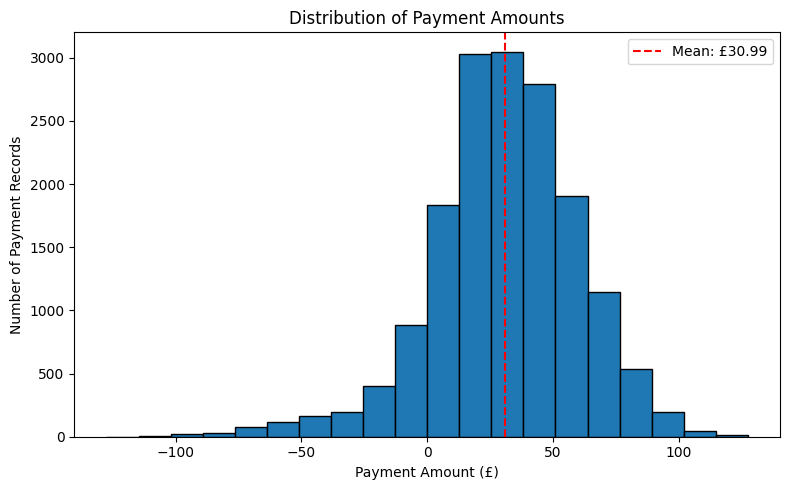

In [14]:
import matplotlib.pyplot as plt

df = tables["payments"]

mean_amount = df["amount"].mean()

plt.figure(figsize=(8, 5))
plt.hist(df["amount"].dropna(), bins=20, edgecolor="black")

plt.axvline(
    mean_amount,
    color="red",
    linestyle="--",
    label=f"Mean: £{mean_amount:.2f}"
)

plt.title("Distribution of Payment Amounts")
plt.xlabel("Payment Amount (£)")
plt.ylabel("Number of Payment Records")
plt.legend()
plt.tight_layout()
plt.show()

the distribution appears to be skewed to the right, with the mean payment being 31 pounds.

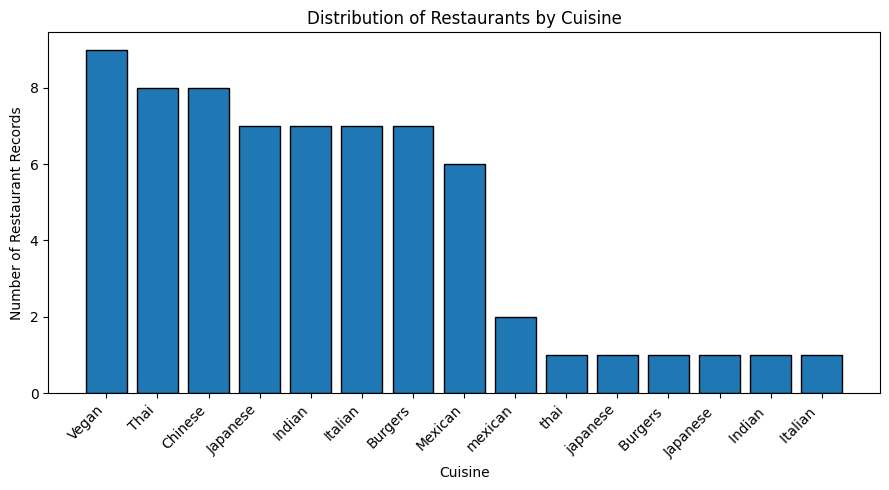

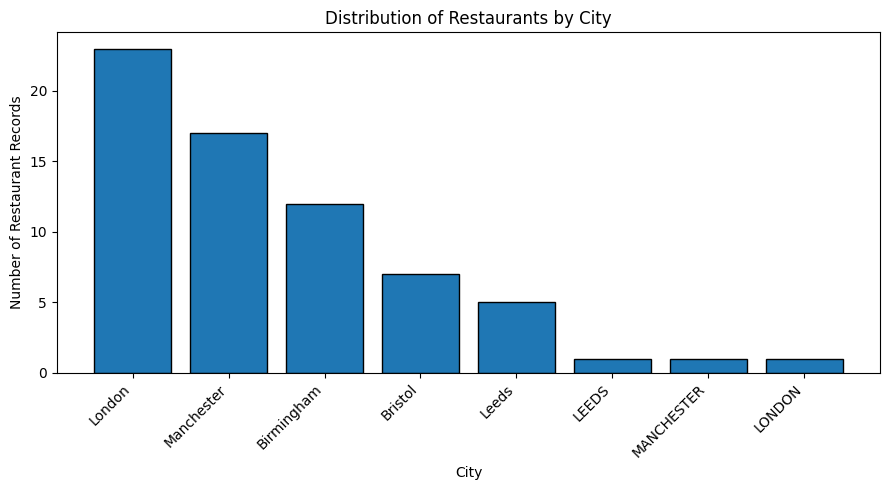

In [15]:
import matplotlib.pyplot as plt

df = tables["restaurants"]

for column in ["cuisine", "city"]:
    counts = df[column].value_counts()

    plt.figure(figsize=(9, 5))
    plt.bar(counts.index, counts.values, edgecolor="black")

    plt.title(f"Distribution of Restaurants by {column.title()}")
    plt.xlabel(column.title())
    plt.ylabel("Number of Restaurant Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

in dist 1 we can see that initially it looked like some cuisines were ordered more than the other however the spellings of each cuisine was recorded incorrectly which created multiple versions of the same cuisine. this  is one of the major errors visble as of now. and the same applies to the 2nd dist where the names are in all caps and normal

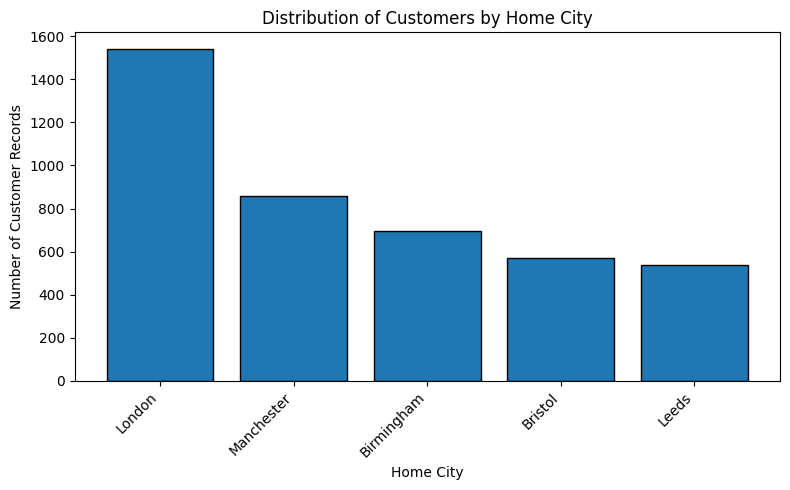

In [16]:
import matplotlib.pyplot as plt

df = tables["customers"]

city_counts = df["home_city"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(city_counts.index, city_counts.values, edgecolor="black")

plt.title("Distribution of Customers by Home City")
plt.xlabel("Home City")
plt.ylabel("Number of Customer Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

this graph shows that most customers are from london

## 4. Check

*Show how you know your answer is right. What did you compare, count or spot check, and what did the checks show? If a check failed, say what you changed.*

Add text here as you go along. Show that you are staying in control of the build!

## 5. Prompts and AI notes

*Paste each prompt you used, as you sent it. Then note what you accepted, what you changed or rejected, and why. Include at least one example where the AI was wrong or needed correcting, if that happened.*

Add prompts here.

## 6. What I could not verify

*Be honest about what remains unchecked, and what you would do next with more time.*

Add text here.

## Self-check before you stop

Tick these off in your head or in a text cell. They mirror the three things the real test is marked on.

**How was the code generated?**
- [ ] Every block of code that matters has a prompt or a source associated with it.
- [ ] I can say what each block is meant to do and what output I expected.

**Evidence of checking**
- [ ] For every table I built, I checked the number of rows against what I expected, and I can say why.
- [ ] I checked that keys I treat as unique are unique, and I looked for duplicates.
- [ ] My final table agrees with the source data in at least one total, and I show the comparison.
- [ ] I looked at individual records, not only at totals.
- [ ] I wrote down at least one thing the checks caught, and what I changed (if possible).

**Interpretation in my own words**
- [ ] I state each decision (week, which orders count, net revenue, delivery time) and why I chose it.
- [ ] I say what the figures can and cannot be trusted for.
- [ ] Section 6 lists what I did not verify, honestly.